# Step 3 — Range Cropping, Cubic Spline Resampling (`1,000` Points) & Ready Corpora Compilation (`01_interim` $\rightarrow$ `02_ready`)

This notebook documents and verifies **Step 3** of the `SPECTRA-BREAST` data engineering pipeline, transforming the physically cleaned native-grid datasets in `data/01_interim/` into the model-ready `1,000`-point tensors in `data/02_ready/`:
1. **Canonical Wavenumber Cropping**: Aligning heterogeneous grating ranges onto shared physical windows (`FP: 650–1750` $\text{cm}^{-1}$, `HW: 2765–3200` $\text{cm}^{-1}$, `CH: 2800–3045` $\text{cm}^{-1}$, and `FR: 650–3200 / 380–3049` $\text{cm}^{-1}$).
2. **Boundary-Clamped Natural Cubic Spline Resampling (`1,000` Points)**: Mapping every spectrum (`500` to `2,670` native channels) onto an exact `1,000`-channel grid with zero boundary blow-up.
3. **Post-Crop `[0, 1]` Re-Anchoring**: Ensuring that cropped sub-windows (such as `FP` extracted from Full-Range `trophy_jena` or `HW` extracted from `pdo_hw_maps`) span the full `[0.0000, 1.0000]` dynamic range and eliminating any $10^{-3}$ cubic spline overshoot.

> **Modular Architecture**: Resampling routines live in `spectrabreast.preprocessing.resampling` and compilation/visualization helpers live in `spectrabreast.preprocessing.ready_atlas`, keeping every notebook cell concise (3–12 lines).

## 1. Environment Setup & Imports
Import standard libraries and the Step 3 utilities from `spectrabreast.preprocessing`.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

from spectrabreast.preprocessing import (
    GRID_FP_1000, GRID_HW_1000, GRID_CH_1000,
    compile_ready_datasets, load_ready_summary_stats,
    plot_ready_architecture_overview, plot_cubic_spline_validation,
    plot_ready_pretrain_corpora, plot_ready_downstream_benchmarks,
)

ROOT = Path('..').resolve()
INTERIM_DIR = ROOT / 'data' / '01_interim'
READY_DIR = ROOT / 'data' / '02_ready'
FIG_DIR = ROOT / 'docs' / 'figures' / '03_ready_compilation'

Interim directory: c:\Users\alexf\Desktop\SPECTRA-BREAST\data\01_interim
Ready directory  : c:\Users\alexf\Desktop\SPECTRA-BREAST\data\02_ready
Canonical grids  : FP=[650.0, 1750.0] (1000 pts), HW=[2765.0, 3200.0] (1000 pts), CH=[2800.0, 3045.0] (1000 pts)


## 2. Master Catalog of Compiled `data/02_ready/` Tensors
Inspect the compiled `1,000`-point `.npz` corpora across `pretrain/` (`1D-ViT SMAE` and `1D-ResNet-34 Barlow Twins`) and `downstream/` (`ibd`, `bacteria_id`, `riverd_oral_hw`, `dataset_renzo`).

In [2]:
ready_df = pd.read_csv(ROOT / 'docs' / 'ready_datasets_catalog.csv')
cols = ['Role', 'Folder', 'Ready_File', 'Grid_Range_cm1', 'Grid_Points', 'Step_cm1', 'Total_Spectra', 'Value_Range']
print(f'Compiled ready dataset archives: {len(ready_df)}')
display(ready_df[cols])

Compiled ready dataset archives: 11


Role,Folder,Ready_File,Grid_Range_cm1,Grid_Points,Step_cm1,Total_Spectra,Value_Range
SSL Pre-Training (ViT-SMAE),pretrain/FP,pretrain_vit_fp_1000.npz,650.00–1750.00,1000,1.1011,384241,"[0.0000, 1.0000]"
SSL Denoising Pre-Training,pretrain/FP,deepr_paired_fp_1000.npz,650.00–1750.00,1000,1.1011,172312,"[0.0000, 1.0000]"
SSL Pre-Training (ViT-SMAE),pretrain/HW,pretrain_vit_hw_1000.npz,2765.00–3200.00,1000,0.4355,448358,"[0.0000, 1.0000]"
SSL Pre-Training (ViT-SMAE),pretrain/CH,pretrain_vit_ch_1000.npz,2800.00–3045.00,1000,0.2454,448358,"[0.0000, 1.0000]"
SSL Pre-Training (Full-Range),pretrain/FR,trophy_jena_fr_1000.npz,650.00–3200.00,1000,2.5526,115913,"[0.0000, 1.0000]"
SSL Pre-Training (1D-ResNet-34 Barlow Twins),pretrain/CNN,pretrain_cnn_all_1000.npz,"Normalized 1,000-ch index",1000,0.0000,716686,"[0.0000, 1.0000]"
Downstream Benchmark (FP),downstream/FP,ibd_fp_1000.npz,650.00–1750.00,1000,1.1011,228,"[0.0000, 1.0000]"
Downstream Benchmark (FP),downstream/FP,bacteria_id_fp_1000.npz,650.00–1750.00,1000,1.1011,6000,"[0.0000, 1.0000]"
Downstream Benchmark (HW),downstream/HW,riverd_oral_hw_1000.npz,2765.00–3200.00,1000,0.4355,8422,"[0.0000, 1.0000]"
Downstream Benchmark (CH),downstream/CH,riverd_oral_ch_1000.npz,2800.00–3045.00,1000,0.2454,8422,"[0.0000, 1.0000]"


## 3. Figure 1 — Canonical `1,000`-Point Spectral Grids & Corpus Routing Architecture
Visualize how each dataset's native wavenumber range (gray bars) is cropped onto the shared `FP` (`650–1750` $\text{cm}^{-1}$), `HW` (`2765–3200` $\text{cm}^{-1}$), and `CH` (`2800–3045` $\text{cm}^{-1}$) windows and routed into the `1D-ViT (SMAE)` and `1D-ResNet-34 (Barlow Twins)` corpora.

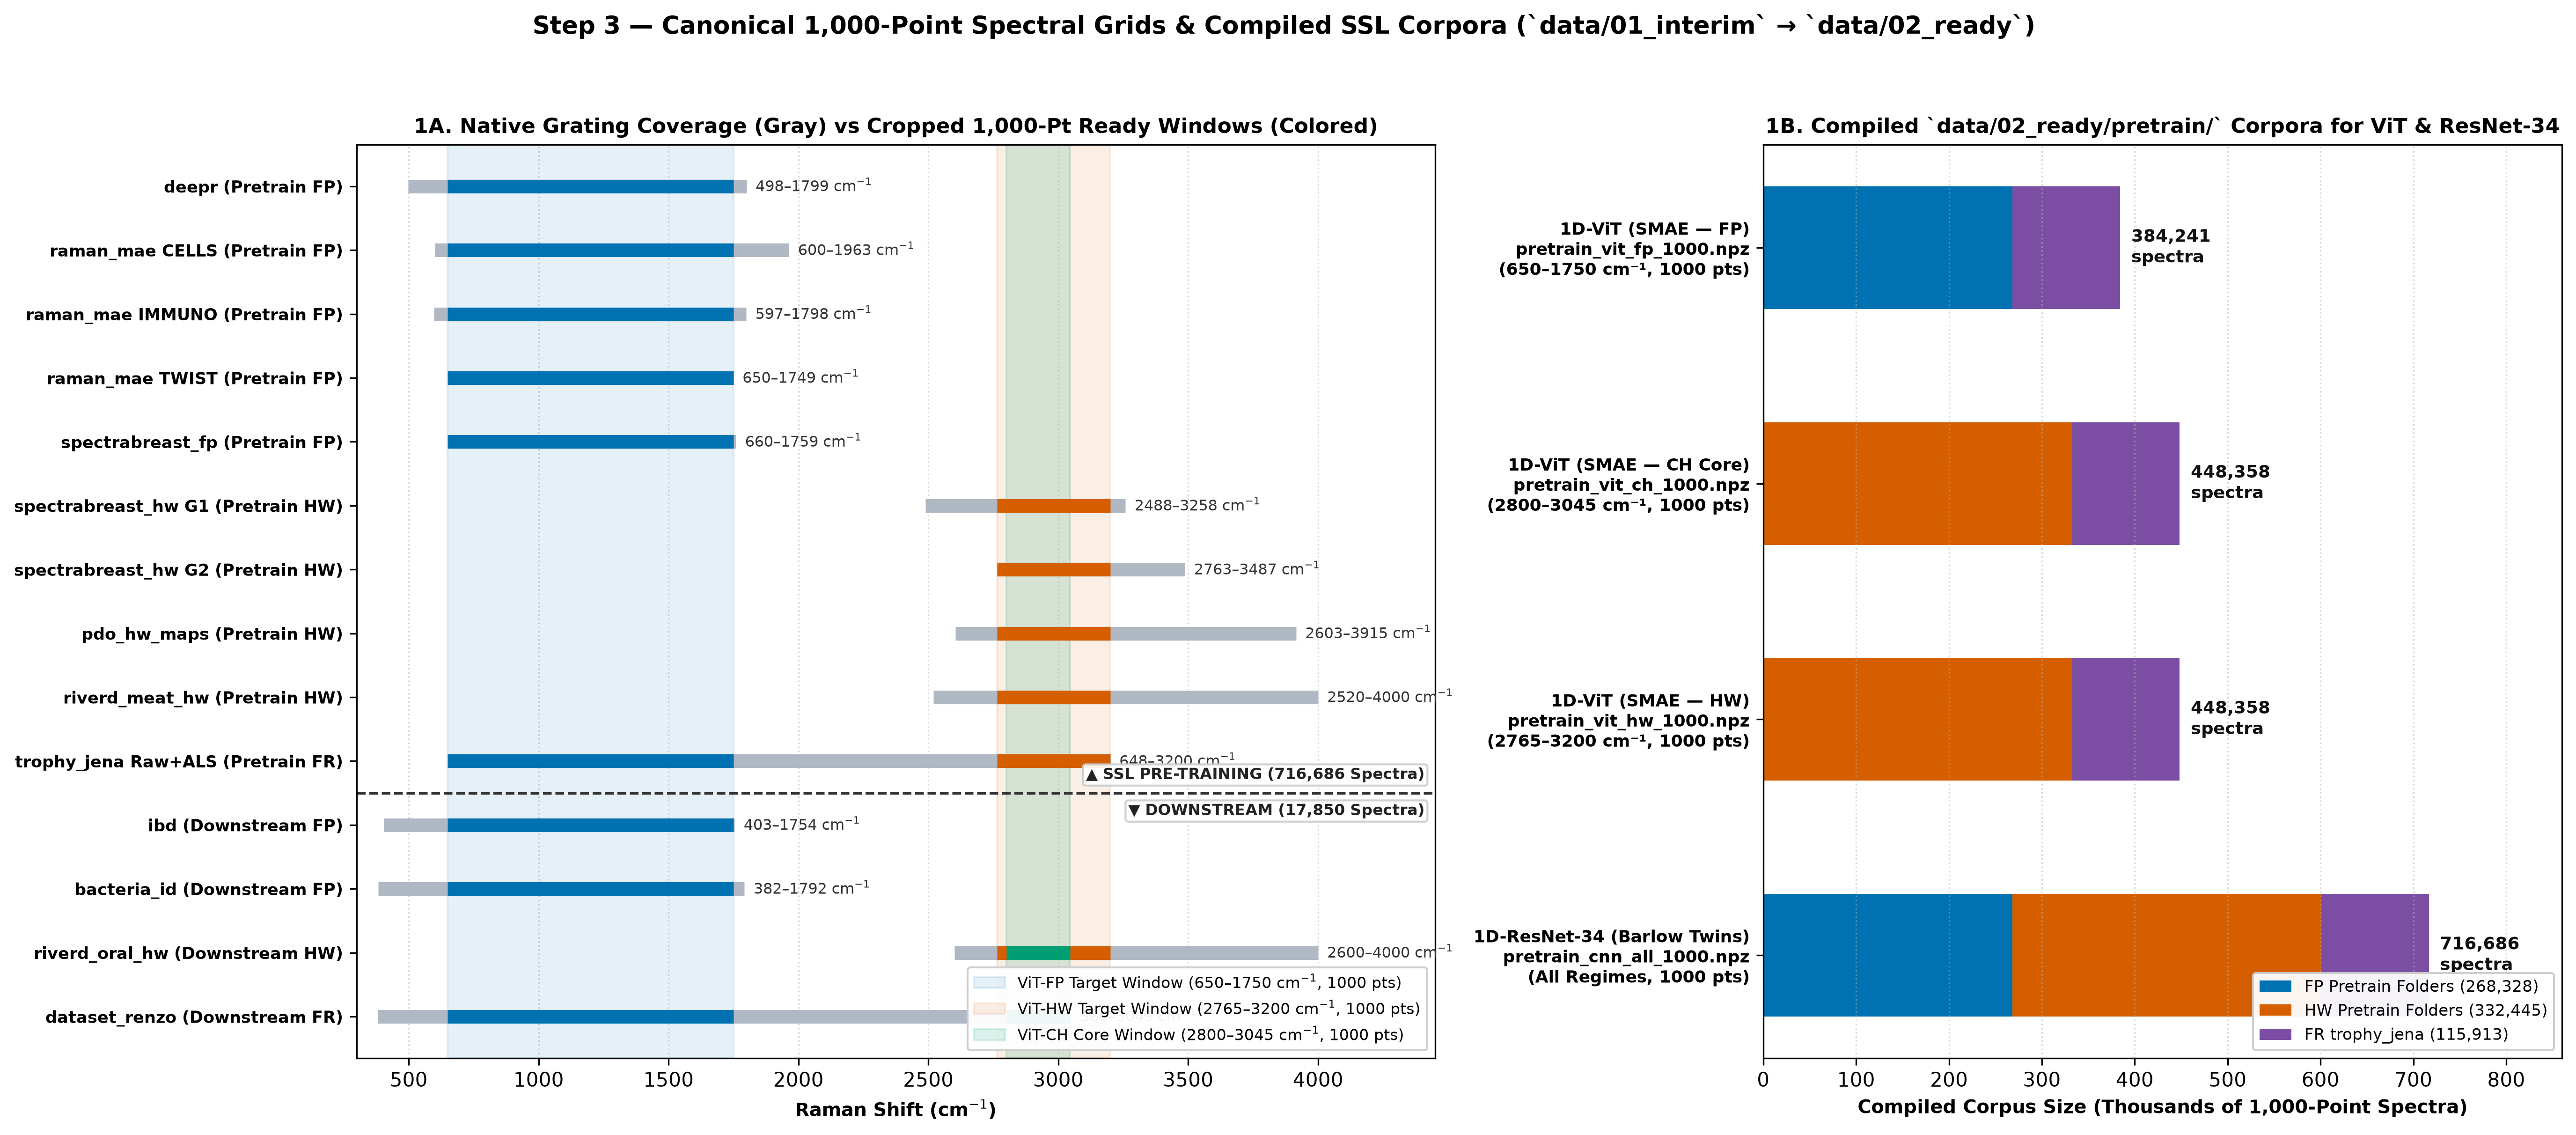

In [3]:
fig1_path = FIG_DIR / 'fig1_ready_grids_and_corpora_architecture.png'
plot_ready_architecture_overview(out_paths=[fig1_path])

## 4. Figure 2 — Physical Validation of Boundary-Clamped Cubic Spline Resampling & Post-Crop `[0, 1]` Re-Anchoring
Verify across 6 representative cohorts (`deepr`, `spectrabreast_fp`, `trophy_jena`, `pdo_hw_maps`, `riverd_oral_hw`, and `dataset_renzo`) that Cubic Spline interpolation to `1,000` points preserves exact Raman band centroids (`1003`, `1445`, `1655`, `2850`, `2930` $\text{cm}^{-1}$) without ringing and restores `[0, 1]` dynamic range after sub-window cropping.

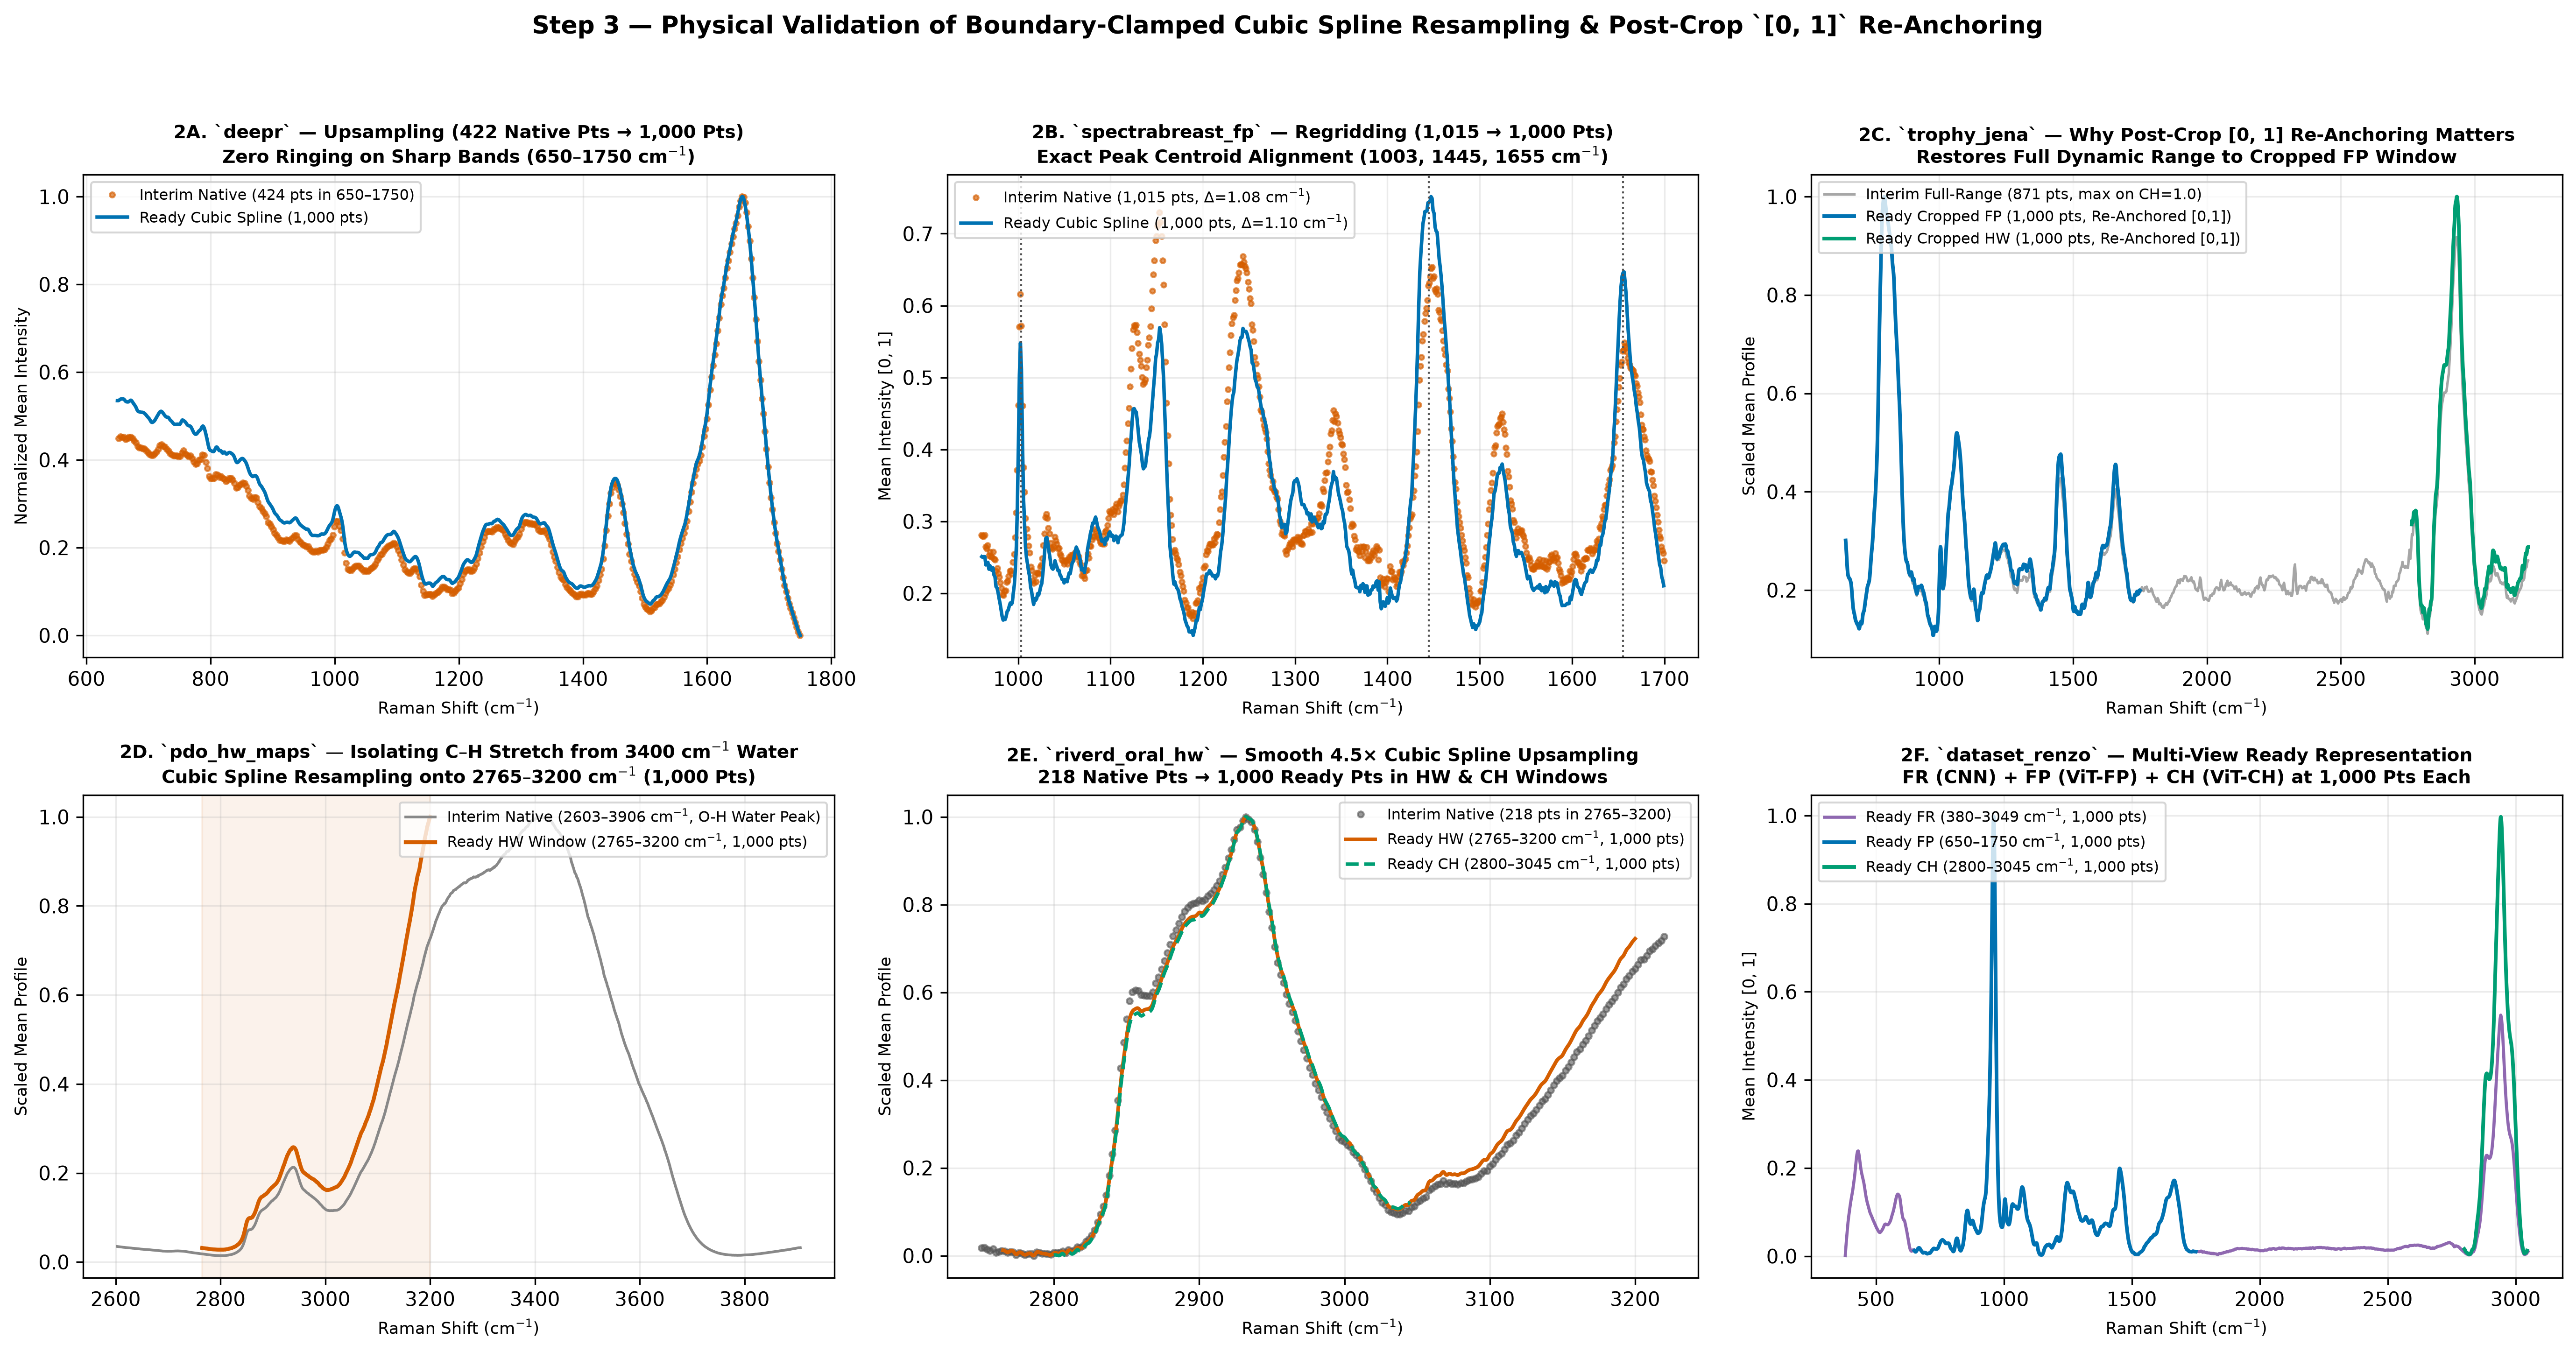

In [4]:
fig2_path = FIG_DIR / 'fig2_cubic_spline_resampling_validation.png'
plot_cubic_spline_validation(INTERIM_DIR, READY_DIR, out_paths=[fig2_path])

## 5. Pre-Training Corpora Verification (`data/02_ready/pretrain/`)
Load the precomputed constituent summary statistics from `pretrain_vit_fp_1000.npz` (`384,241` spectra), `pretrain_vit_hw_1000.npz` (`448,358` spectra), `pretrain_vit_ch_1000.npz` (`448,358` spectra), and `pretrain_cnn_all_1000.npz` (`716,686` unique spectra).

In [5]:
stats = load_ready_summary_stats(READY_DIR)
for key, label in [('fp', 'ViT-FP (650-1750)'), ('hw', 'ViT-HW (2765-3200)'), ('ch', 'ViT-CH (2800-3045)'), ('cnn', 'CNN-All (Multi-Regime)')]:
    c = stats[key]['source_counts']
    names = list(stats[key]['source_names'])
    print(f'{label:24s} | Total N = {int(c.sum()):7,d} | Sources ({len(names)}): {dict(zip(names, map(int, c)))}')

ViT-FP (650-1750)        | Total N = 384,241 | Sources (6): {'deepr_10s': 172312, 'raman_mae_cells': 15429, 'raman_mae_twist': 16496, 'raman_mae_immuno': 11099, 'spectrabreast_fp': 52992, 'trophy_jena_fp': 115913}
ViT-HW (2765-3200)       | Total N = 448,358 | Sources (5): {'spectrabreast_hw_g1': 54810, 'spectrabreast_hw_g2': 81991, 'pdo_hw_maps': 194444, 'riverd_meat_hw': 1200, 'trophy_jena_hw': 115913}
ViT-CH (2800-3045)       | Total N = 448,358 | Sources (5): {'spectrabreast_hw_g1': 54810, 'spectrabreast_hw_g2': 81991, 'pdo_hw_maps': 194444, 'riverd_meat_hw': 1200, 'trophy_jena_ch': 115913}
CNN-All (Multi-Regime)   | Total N = 716,686 | Sources (10): {'deepr_10s': 172312, 'raman_mae_cells': 15429, 'raman_mae_twist': 16496, 'raman_mae_immuno': 11099, 'spectrabreast_fp': 52992, 'spectrabreast_hw_g1': 54810, 'spectrabreast_hw_g2': 81991, 'pdo_hw_maps': 194444, 'riverd_meat_hw': 1200, 'trophy_jena_fr': 115913}


## 6. Figure 3 — Compiled SSL Pre-Training Corpora Profiles (`data/02_ready/pretrain/`)
Render the 2x2 summary grid showing the global $\mu \pm 1\sigma$ envelope and constituent cohort mean profiles for `pretrain_vit_fp_1000.npz`, `pretrain_vit_hw_1000.npz`, `pretrain_vit_ch_1000.npz`, and `pretrain_cnn_all_1000.npz`.

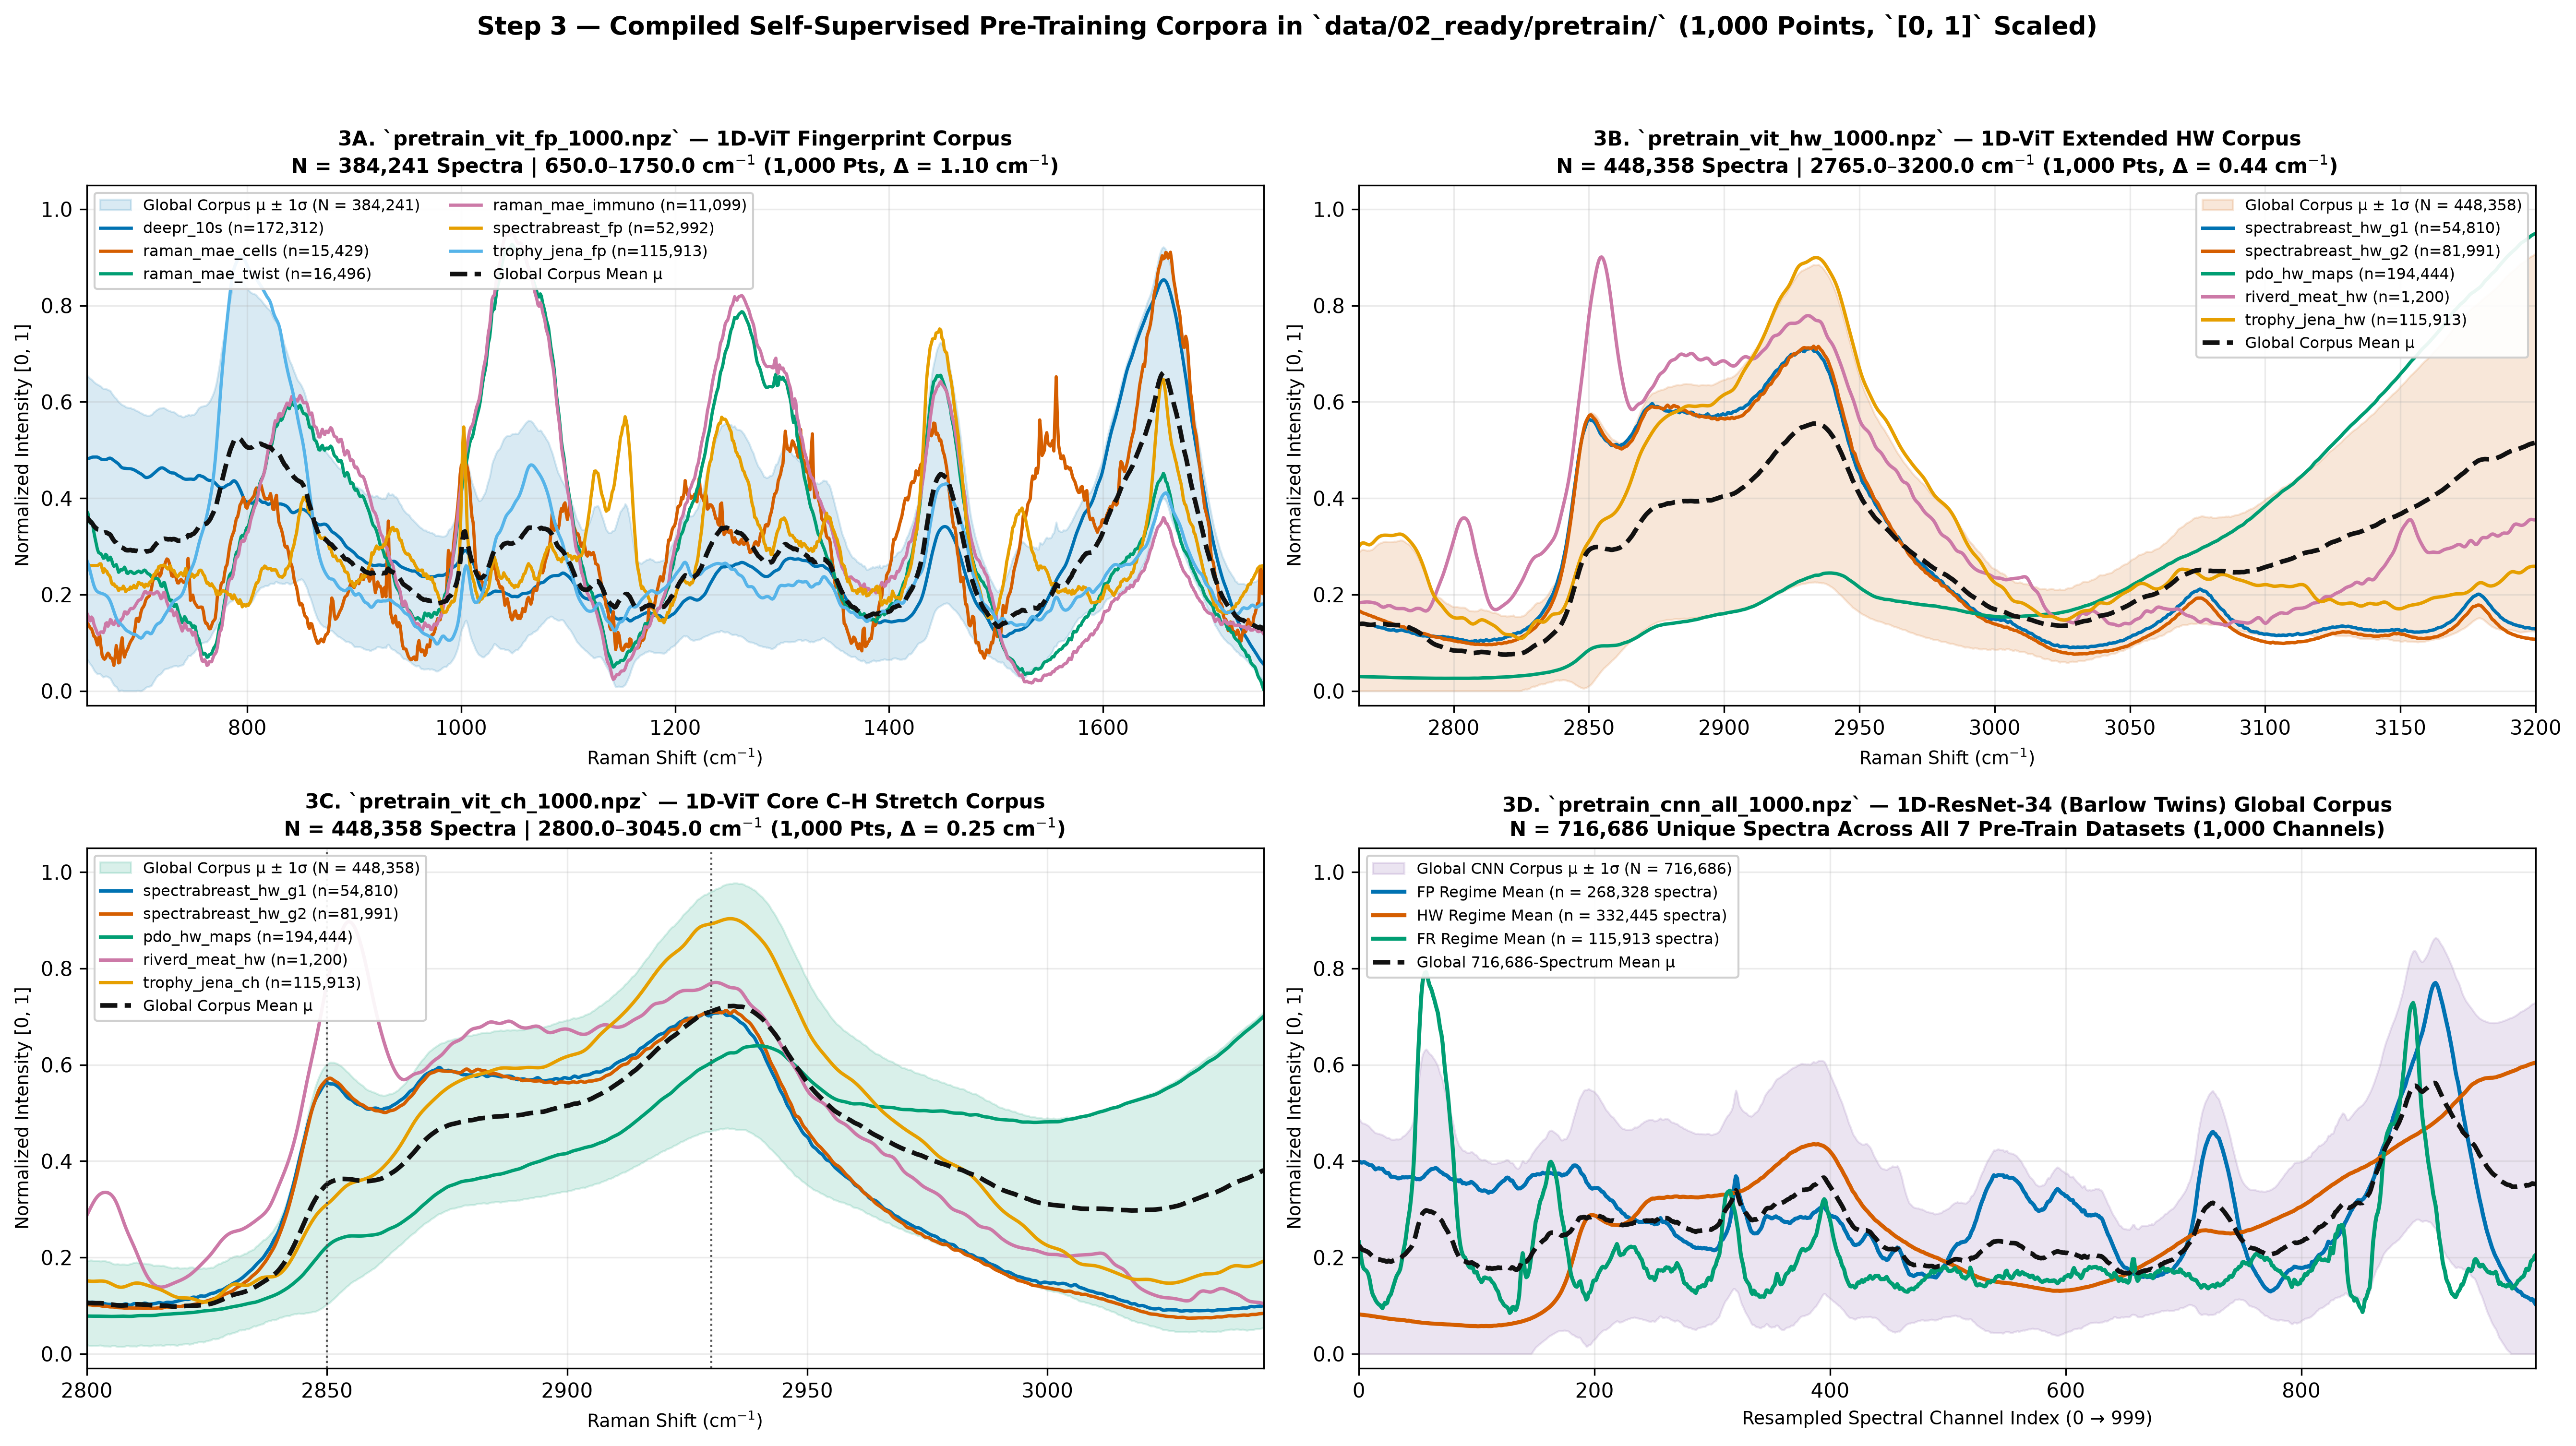

In [6]:
fig3_path = FIG_DIR / 'fig3_ready_pretrain_corpora_profiles.png'
plot_ready_pretrain_corpora(READY_DIR, out_paths=[fig3_path])

## 7. Downstream Benchmarks Verification (`data/02_ready/downstream/`)
Verify shapes, class distributions, and exact `[0.0000, 1.0000]` scaling across the 4 downstream evaluation benchmarks (`ibd`, `bacteria_id`, `riverd_oral_hw`, and `dataset_renzo`).

In [7]:
print('IBD (FP 1000)         :', stats['ibd']['spectra'].shape, '| Classes:', dict(zip(*np.unique(stats['ibd']['labels'], return_counts=True))))
print('Bacteria-ID (FP 1000) :', stats['bact']['X_finetune'].shape, stats['bact']['X_test'].shape, '| 30 species')
print('RiverD Oral (HW 1000) :', stats['oral_hw']['spectra'].shape, '| Classes:', dict(zip(*np.unique(stats['oral_hw']['labels'], return_counts=True))))
print('Dataset Renzo (FR/FP/CH):', stats['renzo']['spectra'].shape, '| Pathologies:', dict(zip(*np.unique(stats['renzo']['pathology'].astype(str), return_counts=True))))

IBD (FP 1000)         : (228, 1000) | Classes: {0: 77, 1: 151}
Bacteria-ID (FP 1000) : (3000, 1000) (3000, 1000) | 30 species
RiverD Oral (HW 1000) : (8422, 1000) | Classes: {0: 5899, 1: 2523}
Dataset Renzo (FR/FP/CH): (3200, 1000) | Pathologies: {'HSCT': 800, 'Rankl-ko': 600, 'WT': 1000, 'oc-oc': 800}


## 8. Figure 4 — Compiled Downstream Evaluation Benchmarks Stratified by Class (`data/02_ready/downstream/`)
Render the 2x3 class-stratified profile grid across all 4 downstream benchmarks on their exact `1,000`-point ready grids.

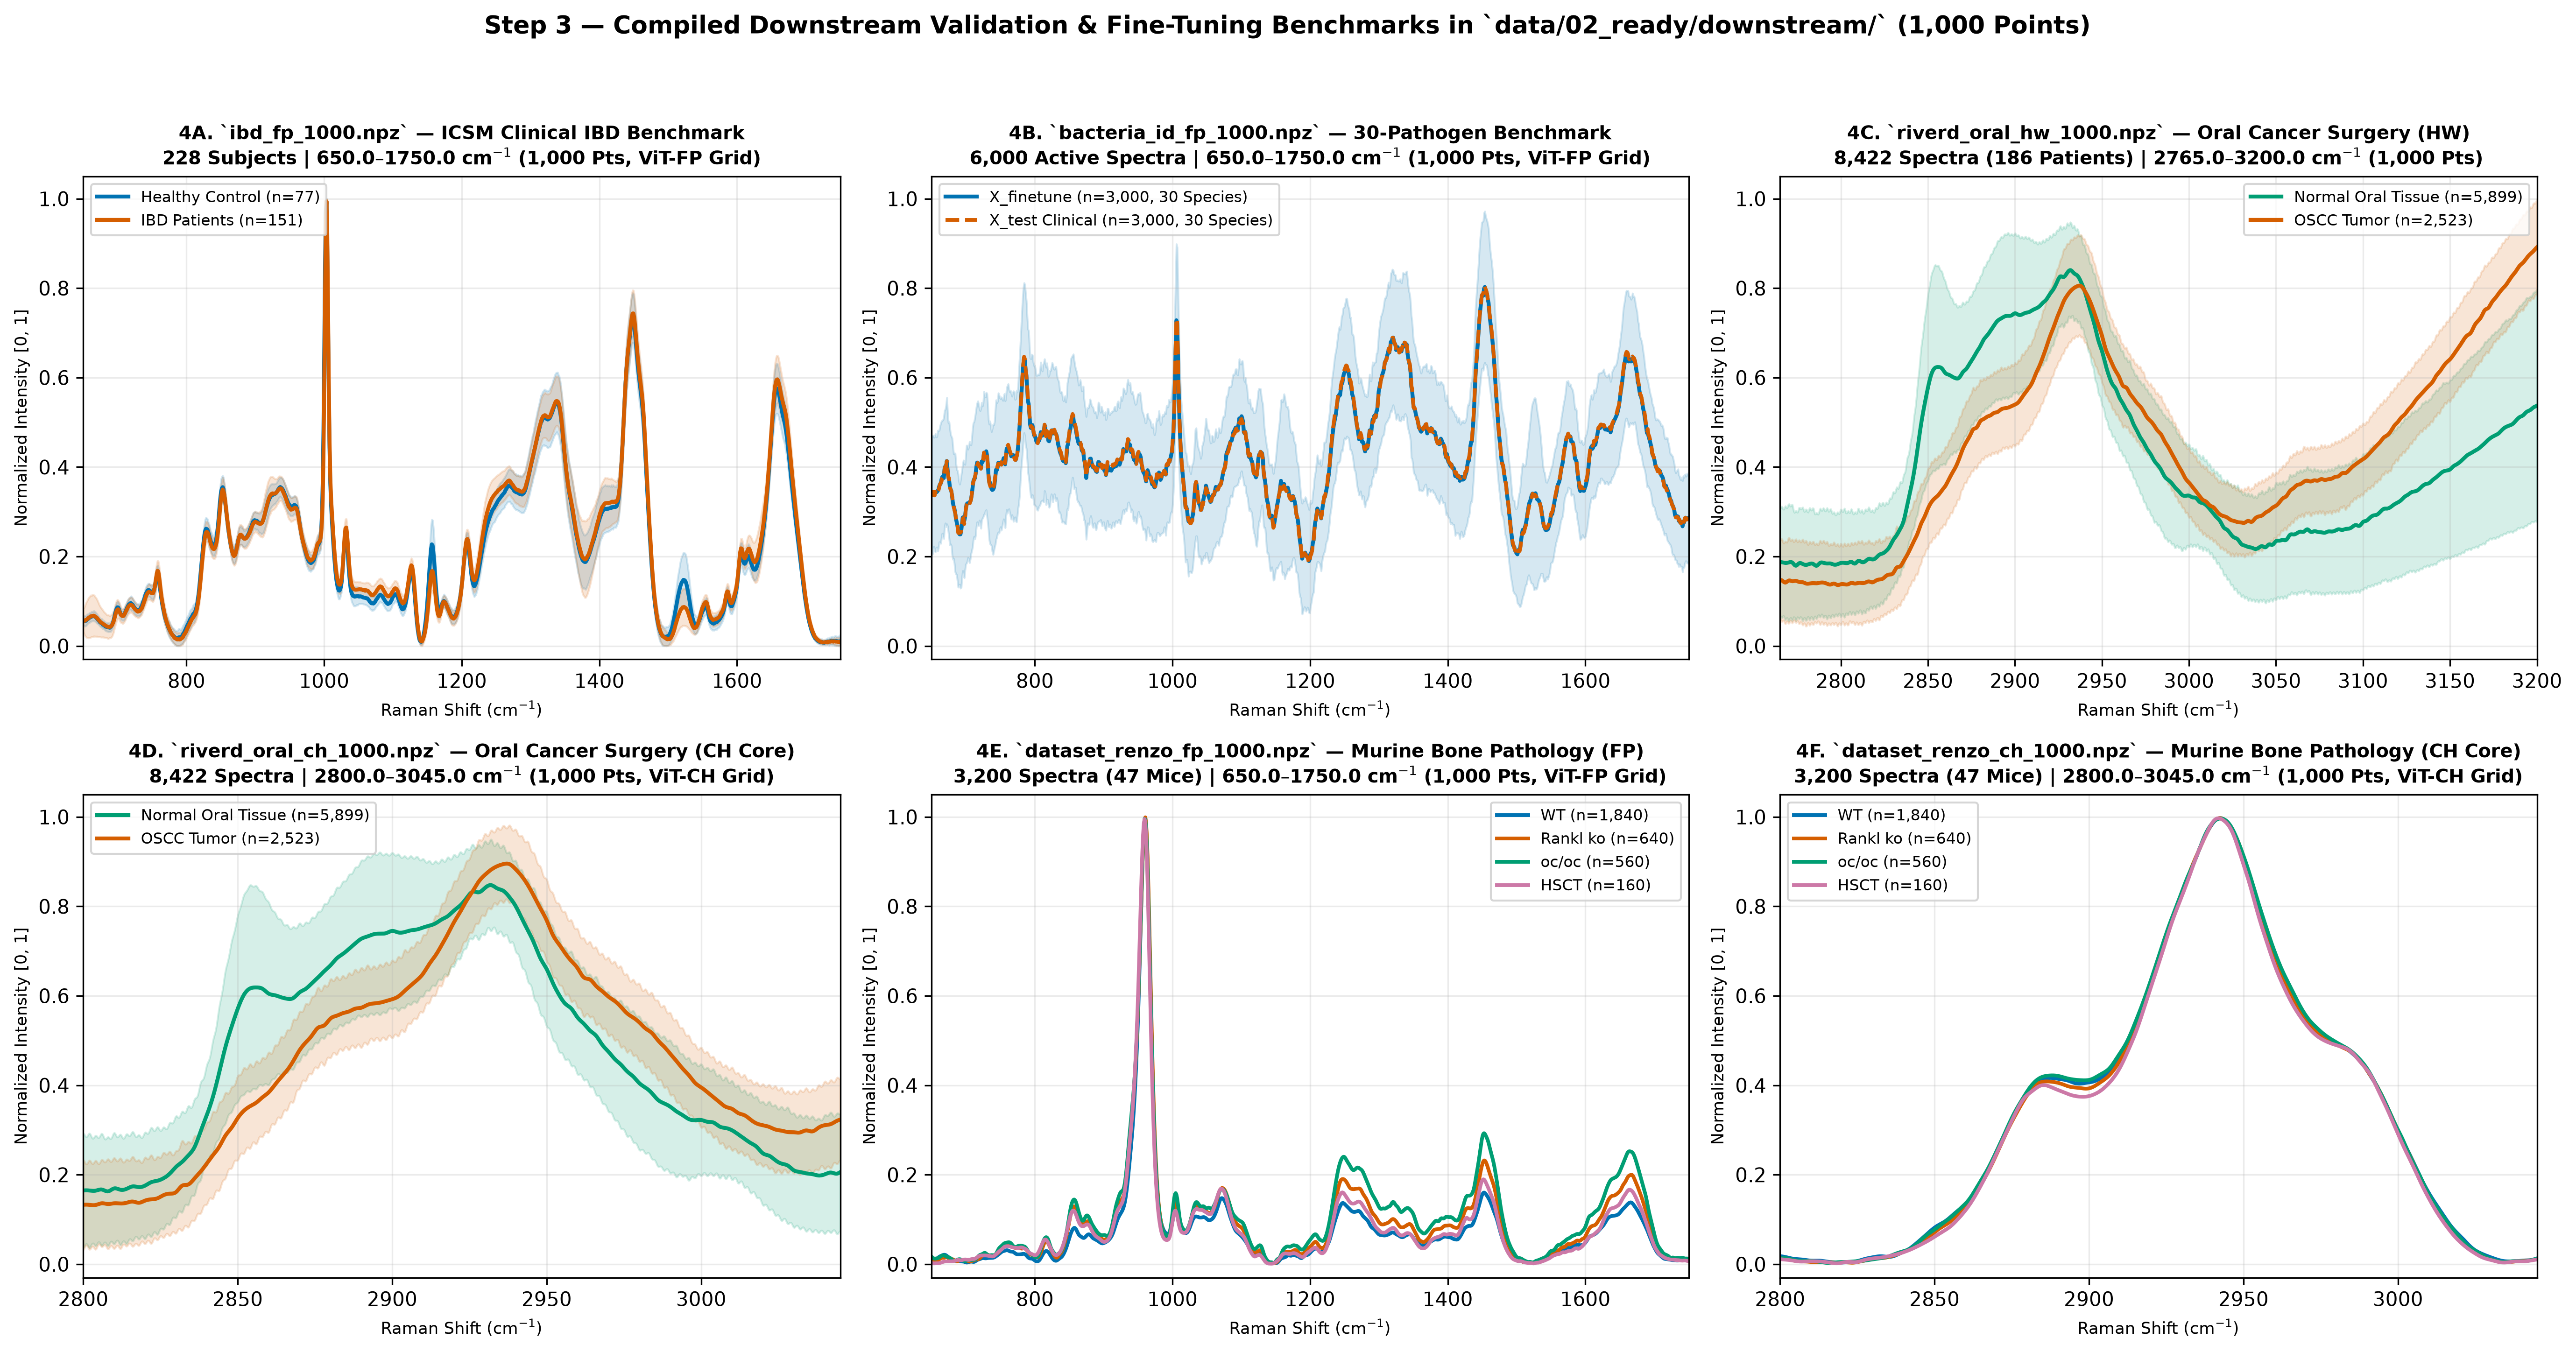

In [8]:
fig4_path = FIG_DIR / 'fig4_ready_downstream_benchmarks_profiles.png'
plot_ready_downstream_benchmarks(READY_DIR, out_paths=[fig4_path])